# CS753 Assignment 1

## Task 1
Implementation of a basic Page Rank algorithm

Set up the modules

In [318]:
import numpy as np
import pandas as pd
import scipy as sp

Some functions for reading and wrangling the data

In [189]:
def read_adjacency_dataset(filename, N):
    with open(filename) as f:
        lines = f.readlines()

    M = sp.sparse.lil_matrix((N, N))

    for l in lines:
        edge_indices = l.strip("\n").split('\t')
        i, j = int(edge_indices[0]), int(edge_indices[1])
        M[i, j] = 1 # Source along cols, destinations along rows

    M_csr = M.tocsr()

    return M_csr


def csr_mat_to_col_stochastic(M_csr):
    col_sums = np.array(M_csr.sum(axis=0)).flatten()
    col_sums[col_sums == 0] = 1

    res =  M_csr.multiply(1 / col_sums)

    return res.tocsr()

**(A) Implementing a basic Pagerank algorithm with iterative form**

Get the M matrix

In [190]:
N = 875713

M_csr = read_adjacency_dataset("web-Google-final.txt", N)

M = csr_mat_to_col_stochastic(M_csr)

Function for a basic Page Rank implementation

In [272]:
from timeit import default_timer as timer

def page_rank(M, max_iter=1000, eps=0.02):
    start = timer()
    
    errs = []
    scores = []
    
    N = M.shape[0]

    r_prev = np.ones(shape=(N, 1)) / N

    num_iters = -1
    
    for i in range(max_iter):
        r_curr = M.dot(r_prev)
        scores.append(r_curr)
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)
        
        if this_error < eps:
            num_iters = i+1
            break
        
        r_prev = r_curr 
    
    print(f"Number of iterations: {num_iters}") 
    print(f"Took {timer() - start:.2f} seconds to complete")

    
    return r_prev, scores, errs, num_iters

Now run the iterative method

In [ ]:
r, scores, errs, i_finish = page_rank(M)

Plot the iteration errors to verify it's converging smoothly

Number of iterations: 26
Took 0.43 seconds to complete


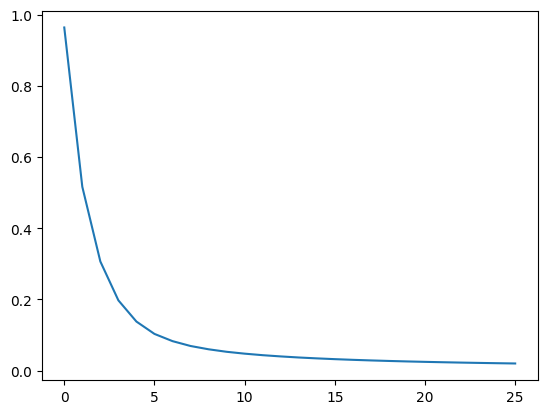

In [273]:
import matplotlib.pyplot as plt

plt.plot(errs)

**(B) extracting top 10 rank scores**

In [293]:
def top_10_ranks(r):
    r_flat = r.flatten()
    r_top_10_IDs = np.argsort(r_flat)[-10:]
    r_top_10_scores = r_flat[r_top_10_IDs]
    
    return r_top_10_IDs, r_top_10_scores

In [294]:
r_top_10_IDs, r_top_10_scores = top_10_ranks(r)

Quickly write the results to Latex for my report

In [295]:
import pandas as pd

def top_ranks_to_latex(top_IDs, top_scores):
    df = pd.DataFrame({
        "Node ID": top_IDs,
        "Node Score": top_scores
    })
    
    df_tex = df.to_latex(index=False, float_format="%.2e")
    print(df_tex)
    
top_ranks_to_latex(r_top_10_IDs, r_top_10_scores)

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
598778 & 7.32e-05 \\
724038 & 7.81e-05 \\
355860 & 7.87e-05 \\
203252 & 7.99e-05 \\
331135 & 8.23e-05 \\
285814 & 8.49e-05 \\
669832 & 8.75e-05 \\
553985 & 9.24e-05 \\
610953 & 1.48e-04 \\
554350 & 1.54e-04 \\
\bottomrule
\end{tabular}



Print out the top 10 nodes and their scores

In [218]:
print("Top 10 IDs")
print(r_top_10_IDs)
print("Top 10 Scores")
print(r_top_10_scores)

Top 10 IDs
[598778 724038 355860 203252 331135 285814 669832 553985 610953 554350]
Top 10 Scores
[7.32268511e-05 7.80700989e-05 7.86794310e-05 7.99145236e-05
 8.23373280e-05 8.48715485e-05 8.75179129e-05 9.24024575e-05
 1.47720808e-04 1.53980643e-04]


Plot the rank scores to get an idea of the distribution

In [243]:
def plot_r_sorted(r):
    plt.plot(np.sort(r.flatten()))

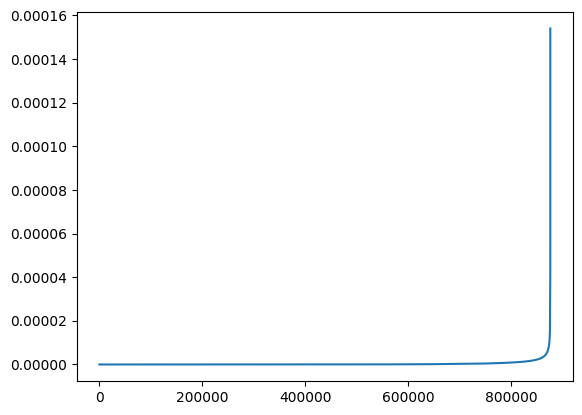

In [244]:
plot_r_sorted(r)

You can see that there is a bunch of score 'accumulating' in just a few nodes

## Task 2

**(A) Finding dead-end nodes**
* Virtually comes down to finding the nodes with no outgoing links. Can simply do the sum down the columns to identify these nodes

In [197]:
def remove_dead_ends(M):
    # Removes dead end nodes from M, and then fixes it back to col stochastic form
    
    M_summed = np.sum(M, axis=0).T
    dead_end_indices = np.argwhere(M_summed == 0)
    non_dead_end_indices = np.argwhere(M_summed > 0)
    non_dead_end_indices_flat = non_dead_end_indices[:, 0]

    M_no_dead_ends = M[:, non_dead_end_indices_flat]
    M_no_dead_ends = M_no_dead_ends[non_dead_end_indices_flat, :]
    
    M_no_dead_ends = csr_mat_to_col_stochastic(M_no_dead_ends)
    
    return M_no_dead_ends, non_dead_end_indices_flat, dead_end_indices

Finding the number of dead ends

In [198]:
M_no_dead_ends, non_dead_end_indices_flat, dead_end_indices = remove_dead_ends(M)

In [278]:
print(f"The number of dead-end nodes was {len(dead_end_indices)}")

The number of dead end nodes was 209692


**(B) Calculating leaked page rank scores**

In [199]:
r_no_dead_ends, r_scores_no_dead_ends, errs_no_dead_ends, i_finish_no_dead_ends = page_rank(M_no_dead_ends)

Number of iterations: 102


In [200]:
r_scores_no_dead_ends_arr = np.squeeze(np.array(r_scores_no_dead_ends))
r_scores = np.squeeze(np.array(scores))

In [201]:
r_scores.shape

(26, 875713)

In [202]:
r_scores_no_dead_ends_arr.shape

(102, 666021)

In [203]:
num_iters = r_scores.shape[0]
leaked_scores = r_scores[:, non_dead_end_indices_flat] - r_scores_no_dead_ends_arr[:num_iters, :]

In [204]:
leaked_scores

array([[-9.42640860e-08, -3.97786585e-08, -2.61055677e-07, ...,
         0.00000000e+00, -2.33185884e-07, -3.19109566e-07],
       [-6.90110957e-08, -1.06105225e-07, -4.96631617e-07, ...,
         0.00000000e+00, -4.01381446e-07, -2.87481707e-07],
       [-1.60078944e-07, -7.21397537e-08, -4.47790425e-07, ...,
         0.00000000e+00, -4.56614191e-07, -2.50215586e-07],
       ...,
       [-3.84758266e-07, -3.45093085e-08, -6.24163911e-07, ...,
         0.00000000e+00, -1.99493927e-06, -1.47852452e-07],
       [-3.79678156e-07, -3.38480521e-08, -6.19922763e-07, ...,
         0.00000000e+00, -2.02353489e-06, -1.42973541e-07],
       [-3.74535080e-07, -3.35923174e-08, -6.15526401e-07, ...,
         0.00000000e+00, -2.05058520e-06, -1.38385515e-07]])

In [205]:
leaked_scores_totals = leaked_scores.sum(axis=1)
leaked_scores_totals_abs = np.abs(leaked_scores_totals)

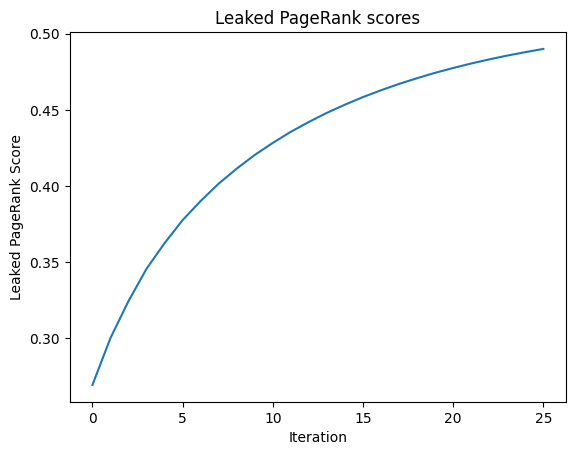

In [282]:
plt.plot(leaked_scores_totals_abs)
plt.title("Leaked PageRank scores")
plt.xlabel("Iteration")
plt.ylabel("Leaked PageRank Score")
plt.savefig("leaked_page_rank.png", dpi=300)

# Task 3

**(A) Adding teleportation**

In [287]:
def page_rank_improved(M, max_iter=1000, eps=0.02, beta=0.9):
    """
    Does page rank to handle both dead ends and spider traps
    """
    # First remove the dead ends
    M, _, _ = remove_dead_ends(M)

    N = M.shape[0]
    r_prev = np.ones(shape=(N, 1)) / N
    
    errs = []
    scores = []
    
    num_iters = -1
    
    start = timer()

    for i in range(max_iter):
        r_curr = beta * M.dot(r_prev) # Step 1
        
        S = np.sum(r_curr) # Step 2
        
        scores.append(r_curr)
        
        r_curr = r_curr + (1 - S) / N # Step 3
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)

        if this_error < eps:
            num_iters = i+1
            break

        r_prev = r_curr


    print(f"Number of iterations: {num_iters}")
    print(f"Took {timer() - start:.2f} seconds to complete")

    return r_prev, scores, errs, num_iters

**(B) Running teleportation code**

In [303]:
r_improved, scores_improved, errs_improved, i_finish_improved = page_rank_improved(M)

KeyboardInterrupt: 

In [296]:
top_ranks_to_latex(*top_10_ranks(r_improved))

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
401859 & 1.06e-04 \\
650977 & 1.06e-04 \\
571519 & 1.08e-04 \\
217250 & 1.21e-04 \\
263779 & 1.23e-04 \\
36651 & 1.24e-04 \\
376003 & 1.34e-04 \\
304835 & 1.39e-04 \\
70355 & 1.69e-04 \\
25111 & 2.20e-04 \\
\bottomrule
\end{tabular}



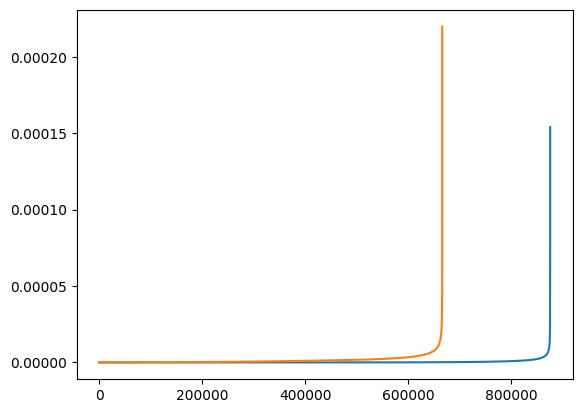

In [261]:
plt.plot(np.sort(r.flatten()))
plt.plot(np.sort(r_improved.flatten()))

You can see in the above, that there the accumulation in the rank score is a bit more subdued - unlike what we saw with the previous case

In [319]:
beta_vals = [1, 0.9, 0.8, 0.7, 0.6]
iterations_vals = []
beta_r_scores = []

for B in beta_vals:
    r, _, _, iters = page_rank_improved(M, beta=B)

    beta_r_scores.append(r)
    
    iterations_vals.append(iters)
    
    print(f"\nFor beta {B}, num iterations is: {iters}")

    print(f"mean rank: {np.mean(r):.2e}\n")


Number of iterations: 108
Took 1.19 seconds to complete

For beta 1, num iterations is: 108
mean rank: 1.50e-06

Number of iterations: 13
Took 0.16 seconds to complete

For beta 0.9, num iterations is: 13
mean rank: 1.50e-06

Number of iterations: 8
Took 0.09 seconds to complete

For beta 0.8, num iterations is: 8
mean rank: 1.50e-06

Number of iterations: 6
Took 0.08 seconds to complete

For beta 0.7, num iterations is: 6
mean rank: 1.50e-06

Number of iterations: 5
Took 0.06 seconds to complete

For beta 0.6, num iterations is: 5
mean rank: 1.50e-06



Plotting beta values and their convergence rates

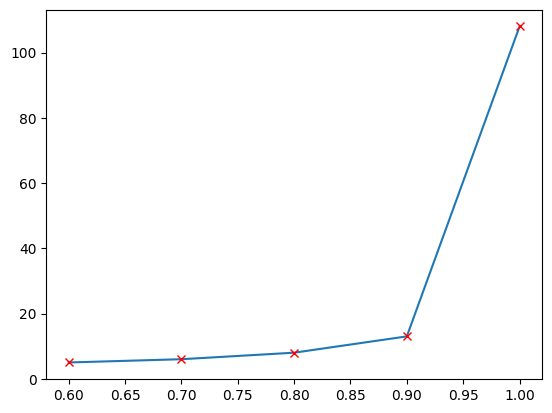

In [269]:
plt.plot(beta_vals, iterations_vals, marker="x", markeredgecolor = "red")

Clearly what is happening that an increase of the Beta value increases the number of iterations for the algo to finish

Writing results to latex for my report

In [317]:
df_beta = pd.DataFrame({
    "Teleportation Probability ($\\beta$)": beta_vals,
    "Iterations to Converge": iterations_vals
})

tex = df_beta.to_latex(index=False, float_format="%.1f")

print(tex)

\begin{tabular}{rr}
\toprule
Teleportation Probability (\beta) & Iterations to Convergence \\
\midrule
1.0 & 108 \\
0.9 & 13 \\
0.8 & 8 \\
0.7 & 6 \\
0.6 & 5 \\
\bottomrule
\end{tabular}

